# FedVocabHAR WISDM Phase 2B

## Cross-subject, label-free representation repair

Phase 2A improved oracle novel separability but reduced held-out known recognition. Phase 2B tests whether sensor-aware augmentation, an acceleration-magnitude channel, label-free pretraining on permitted streams, subject-invariance, and an InceptionTime-style backbone improve cross-subject transfer.

Candidate encoders never receive activity labels. Encoder and checkpoint selection use subject-held-out linear probes on known activities from development subjects. Evaluation subjects remain sealed until selection is complete. Novel labels are used only in the final oracle diagnostic.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
from collections import defaultdict
import copy,json,math,random,warnings,itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Function
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,precision_recall_fscore_support,confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    development_subjects:tuple=tuple(range(1635,1642))
    integration_subjects:tuple=tuple(range(1643,1648))
    evaluation_subjects:tuple=tuple(range(1648,1651))
    known_activities:tuple=('F','G','H','I','K')
    novel_activities:tuple=('L','M','O','P','Q','S')
    embedding_dim:int=64
    ssl_per_subject:int=1200
    dev_probe_per_subject_activity:int=150
    final_probe_per_subject_activity:int=300
    batch_size:int=192
    epochs:int=20
    validation_every:int=4
    learning_rate:float=8e-4
    weight_decay:float=1e-4
    temperature:float=.12
    reconstruction_weight:float=.30
    domain_weight:float=.08
    variance_weight:float=.08
    mask_fraction:float=.25
    known_accuracy_gate:float=.60
    known_i_f1_gate:float=.40
    oracle_novel_f1_gate:float=.70
    novel_l_f1_gate:float=.40
    loso_std_gate:float=.10

CFG=Config()
PROJECT=Path(CFG.project);P0=PROJECT/'artifacts'/'phase0';P0B=PROJECT/'artifacts'/'phase0b';P2A=PROJECT/'artifacts'/'phase2a'
OUT=PROJECT/'artifacts'/'phase2b';OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz';BASELINE_MODEL=P0B/'contrastive_encoder.pt'
P2A_MODEL=P2A/'phase2a_selected_encoder.pt';P2A_META=P2A/'phase2a_selected_encoder.json'
assert CACHE.exists() and BASELINE_MODEL.exists() and P2A_META.exists()
assert not (set(CFG.evaluation_subjects)&(set(CFG.development_subjects)|set(CFG.integration_subjects)))

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE);print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "development_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "embedding_dim": 64,
  "ssl_per_subject": 1200,
  "dev_probe_per_subject_activity": 150,
  "final_probe_per_subject_activity": 300,
  "batch_size": 192,
  "epochs": 20,
  "validation_every": 4,
  "learning_rate": 0.0008,
  "weight_decay": 0.0001,
  "temperature": 0.12,
  "reconstruction_weight": 0.3,
  "domain_weight": 0.08,
  "variance_weight": 0.08,
  "mask_fraction": 0.25,
  "known_accuracy_gate": 0.6,
  "known_i_f1_gate": 0.4,
  "oracle_novel_f1_gate": 0.7,
  "novel_l_f1_gate": 0.4,
  "loso_std_gate": 0.1
}


## Fixed WISDM cache and reference encoders

The Phase Zero-B encoder and development-selected Phase 2A encoder are frozen references. Phase 2B candidates use the same raw watch-accelerometer windows. The fourth input channel, when enabled, is acceleration magnitude computed after each physical augmentation.


In [3]:
d=np.load(CACHE)
x=d['x'].astype(np.float32);subjects=d['subject'].astype(int)
activities=d['activity'].astype(str);positions=d['position'].astype(np.float32)

class BaselineEncoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,q):return F.normalize(self.project(self.body(q).squeeze(-1)),dim=1)

class ResidualBlock(nn.Module):
    def __init__(self,cin,cout,stride=1):
        super().__init__();self.conv1=nn.Conv1d(cin,cout,5,stride=stride,padding=2,bias=False);self.bn1=nn.BatchNorm1d(cout)
        self.conv2=nn.Conv1d(cout,cout,3,padding=1,bias=False);self.bn2=nn.BatchNorm1d(cout)
        self.skip=nn.Identity() if cin==cout and stride==1 else nn.Sequential(nn.Conv1d(cin,cout,1,stride=stride,bias=False),nn.BatchNorm1d(cout))
    def forward(self,q):return F.relu(self.bn2(self.conv2(F.relu(self.bn1(self.conv1(q)))))+self.skip(q))

class Phase2AEncoder(nn.Module):
    def __init__(self,dim,n_known,n_domains,window_length):
        super().__init__();self.stem=nn.Sequential(nn.Conv1d(3,64,7,padding=3,bias=False),nn.BatchNorm1d(64),nn.ReLU())
        self.body=nn.Sequential(ResidualBlock(64,64),ResidualBlock(64,96,2),ResidualBlock(96,128,2),ResidualBlock(128,128),nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim));self.classifier=nn.Linear(dim,n_known)
        self.decoder=nn.Sequential(nn.Linear(dim,256),nn.ReLU(),nn.Linear(256,3*window_length))
        self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def forward(self,q):
        f=F.normalize(self.project(self.body(self.stem(q)).squeeze(-1)),dim=1);return f,self.classifier(f)

try:bck=torch.load(BASELINE_MODEL,map_location='cpu',weights_only=False)
except TypeError:bck=torch.load(BASELINE_MODEL,map_location='cpu')
channel_mean=np.asarray(bck['channel_mean'],dtype=np.float32);channel_std=np.asarray(bck['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std
baseline=BaselineEncoder(int(bck['config']['embedding_dim'])).to(DEVICE);baseline.load_state_dict(bck['state_dict']);baseline.eval()

p2a=None
if P2A_MODEL.exists():
    try:p2ack=torch.load(P2A_MODEL,map_location='cpu',weights_only=False)
    except TypeError:p2ack=torch.load(P2A_MODEL,map_location='cpu')
    p2a=Phase2AEncoder(64,len(CFG.known_activities),10,x.shape[-1]).to(DEVICE)
    p2a.load_state_dict(p2ack['state_dict']);p2a.eval()

def encode_batches(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):
            value=model(torch.from_numpy(data[start:start+batch]).to(DEVICE))
            if isinstance(value,tuple):value=value[0]
            out.append(value.cpu().numpy())
    return np.concatenate(out).astype(np.float32)

print('windows:',x.shape,'Phase 2A reference loaded:',p2a is not None)


windows: (19704, 3, 128) Phase 2A reference loaded: True


## Label-free pretraining pool and sealed evaluation

The self-supervised pool contains development and integration subjects, sampled without reading activity identity. Development labels are exposed only inside the subject-held-out linear-probe evaluator. Evaluation subjects and labels remain untouched until the selected checkpoint is frozen.


In [4]:
rng=np.random.default_rng(CFG.seed)
ssl_subjects=CFG.development_subjects+CFG.integration_subjects
ssl_idx=[]
for subject in ssl_subjects:
    idx=np.where(subjects==subject)[0]
    if len(idx)>CFG.ssl_per_subject:idx=rng.choice(idx,CFG.ssl_per_subject,replace=False)
    ssl_idx.extend(idx.tolist())
ssl_idx=np.asarray(ssl_idx,dtype=int)

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

dev_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.dev_probe_per_subject_activity,CFG.seed+1)
eval_known_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities))[0]
eval_novel_idx=np.where(np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities))[0]
subject_to_domain={s:i for i,s in enumerate(ssl_subjects)}

assert not set(subjects[ssl_idx])&set(CFG.evaluation_subjects)
assert not set(subjects[dev_idx])&set(CFG.evaluation_subjects)
print('SSL windows:',len(ssl_idx),'development probe:',len(dev_idx),'evaluation known/novel:',len(eval_known_idx),len(eval_novel_idx))
print('SSL counts by subject:',dict(zip(*np.unique(subjects[ssl_idx],return_counts=True))))


SSL windows: 12421 development probe: 3585 evaluation known/novel: 825 995
SSL counts by subject: {np.int64(1635): np.int64(935), np.int64(1636): np.int64(935), np.int64(1637): np.int64(1200), np.int64(1638): np.int64(1200), np.int64(1639): np.int64(1200), np.int64(1640): np.int64(1200), np.int64(1641): np.int64(935), np.int64(1643): np.int64(935), np.int64(1644): np.int64(1021), np.int64(1645): np.int64(980), np.int64(1646): np.int64(935), np.int64(1647): np.int64(945)}


## Sensor-aware views and InceptionTime encoder

Augmentations model realistic wearable variation: arbitrary 3-D orientation, amplitude scaling, jitter, temporal shift, and crop-resampling. Magnitude is recomputed from the augmented XYZ signal. The full objective combines NT-Xent contrastive learning, variance regularization, masked reconstruction, and gradient-reversal subject invariance.


In [5]:
raw_ssl=x[ssl_idx]
xyz_mean=raw_ssl.mean(axis=(0,2),keepdims=True).astype(np.float32);xyz_std=(raw_ssl.std(axis=(0,2),keepdims=True)+1e-6).astype(np.float32)
mag=np.sqrt((raw_ssl**2).sum(1,keepdims=True));mag_mean=mag.mean(axis=(0,2),keepdims=True).astype(np.float32);mag_std=(mag.std(axis=(0,2),keepdims=True)+1e-6).astype(np.float32)

def random_rotation(batch):
    q=torch.randn(batch,4,device=DEVICE);q=F.normalize(q,dim=1);w,a,b,c=q.unbind(1)
    return torch.stack([1-2*(b*b+c*c),2*(a*b-c*w),2*(a*c+b*w),
                        2*(a*b+c*w),1-2*(a*a+c*c),2*(b*c-a*w),
                        2*(a*c-b*w),2*(b*c+a*w),1-2*(a*a+b*b)],1).view(batch,3,3)

def sensor_view(raw,use_magnitude=True,strong=True):
    q=raw.clone();rot=random_rotation(len(q));q=torch.bmm(rot,q)
    q=q*(1+torch.randn(len(q),1,1,device=q.device)*(.12 if strong else .06))
    q=q+torch.randn_like(q)*(.035 if strong else .02)
    shifts=torch.randint(-8 if strong else -4,9 if strong else 5,(len(q),),device=q.device)
    time=(torch.arange(q.size(-1),device=q.device)[None,:]-shifts[:,None])%q.size(-1)
    q=torch.gather(q,2,time[:,None,:].expand(-1,q.size(1),-1))
    if strong:
        length=q.size(-1);keep=int(torch.randint(int(.82*length),length+1,(1,),device=q.device).item())
        start=int(torch.randint(0,length-keep+1,(1,),device=q.device).item())
        q=F.interpolate(q[:,:,start:start+keep],size=length,mode='linear',align_corners=False)
    mean=torch.as_tensor(xyz_mean,device=q.device);std=torch.as_tensor(xyz_std,device=q.device);xyz=(q-mean)/std
    if not use_magnitude:return xyz
    m=torch.sqrt((q*q).sum(1,keepdim=True)+1e-8)
    m=(m-torch.as_tensor(mag_mean,device=q.device))/torch.as_tensor(mag_std,device=q.device)
    return torch.cat([xyz,m],1)

def deterministic_input(raw,use_magnitude):
    xyz=(raw-xyz_mean)/xyz_std
    if not use_magnitude:return xyz.astype(np.float32)
    m=np.sqrt((raw*raw).sum(1,keepdims=True));m=(m-mag_mean)/mag_std
    return np.concatenate([xyz,m],1).astype(np.float32)

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False)
        self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False))
        self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin,dim,n_domains):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32)
        self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
        self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def sequence(self,q):return F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)))
    def forward(self,q,return_sequence=False):
        seq=self.sequence(q);emb=F.normalize(self.project(seq.mean(-1)),dim=1)
        return (emb,seq) if return_sequence else emb

class GradientReverse(Function):
    @staticmethod
    def forward(ctx,q,lambd):ctx.lambd=lambd;return q.view_as(q)
    @staticmethod
    def backward(ctx,grad):return -ctx.lambd*grad,None

def ntxent(z1,z2,temp):
    z=torch.cat([z1,z2],0);sim=z@z.T/temp;n=len(z1);eye=torch.eye(2*n,dtype=torch.bool,device=z.device)
    sim=sim.masked_fill(eye,-1e9);target=torch.cat([torch.arange(n,2*n,device=z.device),torch.arange(n,device=z.device)])
    return F.cross_entropy(sim,target)

def variance_loss(z):
    return F.relu(1-torch.sqrt(z.var(0)+1e-4)).mean()


## Subject-held-out development evaluation

For every candidate and checkpoint, seven probes are fitted. Each probe trains on six development subjects and tests on the remaining subject. The selection score rewards mean macro-F1 and activity-I F1 while penalizing cross-subject variance and calibration error:

`score = macro-F1 + 0.20 × I-F1 − 0.10 × SD − 0.05 × ECE`

This score and all checkpoints are fixed before final evaluation.


In [6]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
all_activities=CFG.known_activities+CFG.novel_activities;all_to_index={a:i for i,a in enumerate(all_activities)}

def ece_score(true,pred,confidence,bins=10):
    correct=(true==pred).astype(float);ece=0.;edges=np.linspace(0,1,bins+1)
    for lo,hi in zip(edges[:-1],edges[1:]):
        q=(confidence>lo)&(confidence<=hi)
        if q.any():ece+=q.mean()*abs(correct[q].mean()-confidence[q].mean())
    return float(ece)

def fit_probe(train_e,train_y,test_e,test_y,labels):
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=1800,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(train_e,train_y);pred=pipe.predict(test_e);prob=pipe.predict_proba(test_e)
    f1s=precision_recall_fscore_support(test_y,pred,labels=labels,zero_division=0)[2]
    return pipe,{'accuracy':float(accuracy_score(test_y,pred)),'macro_f1':float(np.mean(f1s)),'ece':ece_score(test_y,pred,prob.max(1)),'pred':pred,'per_class_f1':f1s}

def loso_score(emb):
    rows=[];y=np.asarray([known_to_index[a] for a in activities[dev_idx]])
    for held in CFG.development_subjects:
        test=subjects[dev_idx]==held;train=~test
        _,m=fit_probe(emb[train],y[train],emb[test],y[test],list(range(len(CFG.known_activities))))
        rows.append({'held_subject':held,'accuracy':m['accuracy'],'macro_f1':m['macro_f1'],'i_f1':float(m['per_class_f1'][known_to_index['I']]),'ece':m['ece']})
    frame=pd.DataFrame(rows);summary={'loso_accuracy':frame.accuracy.mean(),'loso_macro_f1':frame.macro_f1.mean(),
        'loso_macro_f1_std':frame.macro_f1.std(ddof=0),'loso_i_f1':frame.i_f1.mean(),'loso_ece':frame.ece.mean()}
    summary['selection_score']=summary['loso_macro_f1']+.20*summary['loso_i_f1']-.10*summary['loso_macro_f1_std']-.05*summary['loso_ece']
    return frame,summary


## Train label-free Phase 2B ablations

- **SSL-XYZ:** contrastive InceptionTime using XYZ.
- **SSL-Magnitude:** adds the orientation-resistant magnitude channel.
- **SSL-Magnitude-Domain:** adds subject-adversarial learning.
- **SSL-Full:** adds masked reconstruction to the magnitude and subject-invariant model.


In [7]:
CANDIDATES={
 'inception_ssl_xyz':{'magnitude':False,'domain':False,'reconstruction':False},
 'inception_ssl_mag':{'magnitude':True,'domain':False,'reconstruction':False},
 'inception_ssl_mag_domain':{'magnitude':True,'domain':True,'reconstruction':False},
 'inception_ssl_full':{'magnitude':True,'domain':True,'reconstruction':True}}

def train_candidate(name,spec):
    seed_all(CFG.seed);cin=4 if spec['magnitude'] else 3
    model=InceptionEncoder(cin,CFG.embedding_dim,len(ssl_subjects)).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    rng=np.random.default_rng(CFG.seed);best=-1e9;best_state=None;history=[];fold_history=[]
    dev_input=deterministic_input(x[dev_idx],spec['magnitude'])
    for epoch in range(1,CFG.epochs+1):
        model.train();order=rng.permutation(ssl_idx);losses=[]
        for start in range(0,len(order),CFG.batch_size):
            idx=order[start:start+CFG.batch_size]
            if len(idx)<16:continue
            raw=torch.from_numpy(x[idx]).to(DEVICE);v1=sensor_view(raw,spec['magnitude'],True);v2=sensor_view(raw,spec['magnitude'],True)
            opt.zero_grad();z1=model(v1);z2=model(v2);loss=ntxent(z1,z2,CFG.temperature)+CFG.variance_weight*(variance_loss(z1)+variance_loss(z2))
            if spec['domain']:
                domains=torch.tensor([subject_to_domain[int(s)] for s in subjects[idx]],device=DEVICE)
                loss=loss+CFG.domain_weight*F.cross_entropy(model.domain(GradientReverse.apply((z1+z2)/2,1.0)),domains)
            if spec['reconstruction']:
                clean=sensor_view(raw,spec['magnitude'],False);masked=clean.clone();length=max(1,int(clean.size(-1)*CFG.mask_fraction))
                starts=torch.randint(0,clean.size(-1)-length+1,(len(clean),),device=DEVICE)
                timeline=torch.arange(clean.size(-1),device=DEVICE)[None,:]
                time_mask=(timeline>=starts[:,None])&(timeline<(starts+length)[:,None])
                masked=masked.masked_fill(time_mask[:,None,:],0)
                _,seq=model(masked,True);recon=model.decoder(seq);mask=torch.zeros_like(clean)
                mask=time_mask[:,None,:].expand_as(clean).to(clean.dtype)
                rec=((recon-clean).pow(2)*mask).sum()/mask.sum().clamp_min(1)
                loss=loss+CFG.reconstruction_weight*rec
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.0);opt.step();losses.append(float(loss.detach().cpu()))
        row={'model':name,'epoch':epoch,'loss':float(np.mean(losses))}
        if epoch%CFG.validation_every==0 or epoch==CFG.epochs:
            emb=encode_batches(model,dev_input);folds,summary=loso_score(emb);row.update(summary)
            folds['model']=name;folds['epoch']=epoch;fold_history.extend(folds.to_dict('records'))
            if summary['selection_score']>best:
                best=summary['selection_score'];best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_summary=summary.copy();best_epoch=epoch
            print(name,'epoch',epoch,'loss',round(row['loss'],4),'LOSO F1',round(summary['loso_macro_f1'],4),'score',round(summary['selection_score'],4))
        history.append(row)
    model.load_state_dict(best_state);model.eval()
    torch.save({'state_dict':best_state,'config':asdict(CFG),'model_name':name,'spec':spec,'best_epoch':best_epoch,
                'selection':best_summary,'xyz_mean':xyz_mean,'xyz_std':xyz_std,'mag_mean':mag_mean,'mag_std':mag_std},OUT/f'{name}.pt')
    return model,history,fold_history,{'model':name,'best_epoch':best_epoch,**best_summary,**spec}

trained={};history=[];fold_history=[];selection_rows=[]
for name,spec in CANDIDATES.items():
    model,h,fh,s=train_candidate(name,spec);trained[name]=model;history.extend(h);fold_history.extend(fh);selection_rows.append(s)
pd.DataFrame(history).to_csv(OUT/'phase2b_training_history.csv',index=False)
pd.DataFrame(fold_history).to_csv(OUT/'phase2b_loso_folds.csv',index=False)
selection=pd.DataFrame(selection_rows).sort_values('selection_score',ascending=False);selection.to_csv(OUT/'phase2b_selection_results.csv',index=False)
SELECTED_ENCODER=str(selection.iloc[0].model)
print('selected encoder:',SELECTED_ENCODER);display(selection.round(4))


inception_ssl_xyz epoch 4 loss 4.3138 LOSO F1 0.2815 score 0.2871
inception_ssl_xyz epoch 8 loss 3.6959 LOSO F1 0.1703 score 0.1676
inception_ssl_xyz epoch 12 loss 3.4031 LOSO F1 0.2191 score 0.2359
inception_ssl_xyz epoch 16 loss 3.2513 LOSO F1 0.2756 score 0.2818
inception_ssl_xyz epoch 20 loss 3.0238 LOSO F1 0.3026 score 0.323
inception_ssl_mag epoch 4 loss 3.7617 LOSO F1 0.2939 score 0.3328
inception_ssl_mag epoch 8 loss 3.1667 LOSO F1 0.2422 score 0.2626
inception_ssl_mag epoch 12 loss 2.7727 LOSO F1 0.3307 score 0.3712
inception_ssl_mag epoch 16 loss 2.4588 LOSO F1 0.371 score 0.411
inception_ssl_mag epoch 20 loss 2.18 LOSO F1 0.3093 score 0.3476
inception_ssl_mag_domain epoch 4 loss 3.904 LOSO F1 0.2685 score 0.2831
inception_ssl_mag_domain epoch 8 loss 3.4025 LOSO F1 0.3753 score 0.4379
inception_ssl_mag_domain epoch 12 loss 2.9576 LOSO F1 0.3707 score 0.4278
inception_ssl_mag_domain epoch 16 loss 2.6411 LOSO F1 0.3404 score 0.3692
inception_ssl_mag_domain epoch 20 loss 2.344 L

,model,best_epoch,loso_accuracy,loso_macro_f1,loso_macro_f1_std,loso_i_f1,loso_ece,selection_score,magnitude,domain,reconstruction
3,inception_ssl_full,8,0.4220,0.3673,0.1150,0.5687,0.3144,0.4539,True,True,True
2,inception_ssl_mag_domain,8,0.4376,0.3753,0.1292,0.4723,0.3796,0.4379,True,True,False
1,inception_ssl_mag,16,0.4234,0.3710,0.1439,0.3470,0.3002,0.4110,True,False,False
0,inception_ssl_xyz,20,0.3923,0.3026,0.1746,0.2976,0.4339,0.3230,False,False,False


## Frozen final evaluation and oracle representation diagnostic

The selected encoder is now frozen. Final known probes use development labels only. The oracle combined-vocabulary probe may use integration-client novel labels solely to measure whether the representation can separate the expanded vocabulary.


In [8]:
reference_embeddings={'phase0b_contrastive':encode_batches(baseline,xn)}
if p2a is not None:reference_embeddings['phase2a_ce_supcon']=encode_batches(p2a,xn)
candidate_embeddings={}
for name,model in trained.items():candidate_embeddings[name]=encode_batches(model,deterministic_input(x,CANDIDATES[name]['magnitude']))
embeddings={**reference_embeddings,**candidate_embeddings}

known_probe_idx=limited_by_group(CFG.development_subjects,CFG.known_activities,CFG.final_probe_per_subject_activity,CFG.seed+10)
oracle_novel_idx=limited_by_group(CFG.integration_subjects,CFG.novel_activities,CFG.final_probe_per_subject_activity,CFG.seed+11)
oracle_train_idx=np.concatenate([known_probe_idx,oracle_novel_idx]);eval_all_idx=np.concatenate([eval_known_idx,eval_novel_idx])
known_probe_y=np.asarray([known_to_index[a] for a in activities[known_probe_idx]])
eval_known_y=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
oracle_train_y=np.asarray([all_to_index[a] for a in activities[oracle_train_idx]])
eval_all_y=np.asarray([all_to_index[a] for a in activities[eval_all_idx]])

result_rows=[];class_rows=[];confusion_rows=[]
for name,e in embeddings.items():
    _,known=fit_probe(e[known_probe_idx],known_probe_y,e[eval_known_idx],eval_known_y,list(range(len(CFG.known_activities))))
    _,oracle=fit_probe(e[oracle_train_idx],oracle_train_y,e[eval_all_idx],eval_all_y,list(range(len(all_activities))))
    novel_true=eval_all_y[len(eval_known_idx):];novel_pred=oracle['pred'][len(eval_known_idx):]
    novel_f1s=precision_recall_fscore_support(novel_true,novel_pred,labels=[all_to_index[a] for a in CFG.novel_activities],zero_division=0)[2]
    result_rows.append({'model':name,'known_accuracy':known['accuracy'],'known_macro_f1':known['macro_f1'],
        'known_i_f1':float(known['per_class_f1'][known_to_index['I']]),'known_ece':known['ece'],
        'oracle_known_accuracy':float(accuracy_score(eval_all_y[:len(eval_known_idx)],oracle['pred'][:len(eval_known_idx)])),
        'oracle_novel_macro_f1':float(np.mean(novel_f1s)),'oracle_l_f1':float(novel_f1s[list(CFG.novel_activities).index('L')]),
        'oracle_combined_macro_f1':oracle['macro_f1'],'oracle_ece':oracle['ece'],'selected_on_development':name==SELECTED_ENCODER})
    for a,f in zip(CFG.known_activities,known['per_class_f1']):class_rows.append({'model':name,'probe':'known','activity':a,'f1':float(f)})
    for a,f in zip(CFG.novel_activities,novel_f1s):class_rows.append({'model':name,'probe':'oracle_novel','activity':a,'f1':float(f)})
    cm=confusion_matrix(eval_all_y,oracle['pred'],labels=list(range(len(all_activities))))
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):confusion_rows.append({'model':name,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})

results=pd.DataFrame(result_rows);per_class=pd.DataFrame(class_rows);confusions=pd.DataFrame(confusion_rows)
results.to_csv(OUT/'phase2b_final_results.csv',index=False);per_class.to_csv(OUT/'phase2b_per_class_f1.csv',index=False);confusions.to_csv(OUT/'phase2b_oracle_confusions.csv',index=False)
display(results.round(4))


,model,known_accuracy,known_macro_f1,known_i_f1,known_ece,oracle_known_accuracy,oracle_novel_macro_f1,oracle_l_f1,oracle_combined_macro_f1,oracle_ece,selected_on_development
0,phase0b_contrastive,0.5261,0.5192,0.3780,0.3605,0.3721,0.5197,0.1742,0.4077,0.3851,False
1,phase2a_ce_supcon,0.4812,0.5011,0.3054,0.3776,0.3127,0.5839,0.2199,0.4346,0.2936,False
2,inception_ssl_xyz,0.5455,0.5374,0.2656,0.3038,0.5030,0.7483,0.5366,0.5950,0.1240,False
3,inception_ssl_mag,0.5309,0.5215,0.3887,0.2783,0.3891,0.7449,0.4603,0.5330,0.1531,False
4,inception_ssl_mag_domain,0.5709,0.5716,0.3969,0.2870,0.5200,0.7211,0.4333,0.5961,0.1544,False
5,inception_ssl_full,0.5830,0.5884,0.5667,0.2679,0.4570,0.7225,0.3319,0.5785,0.1703,True


## Visual diagnostics, gates, and decision


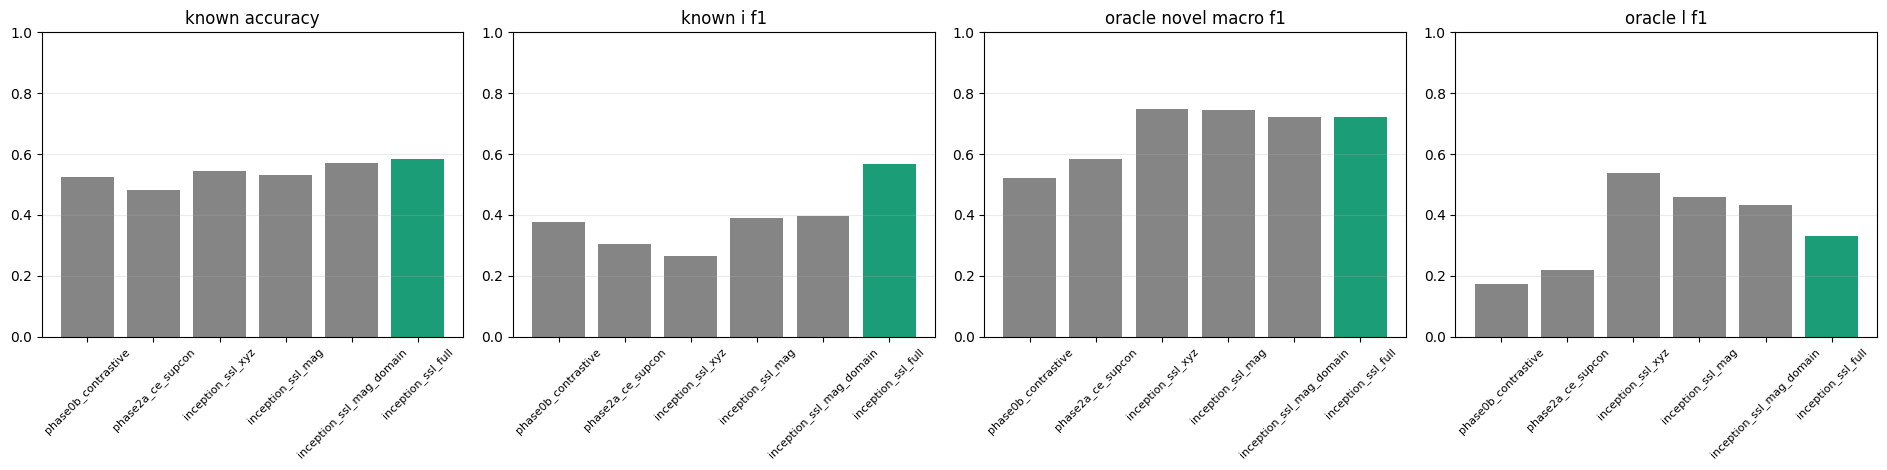

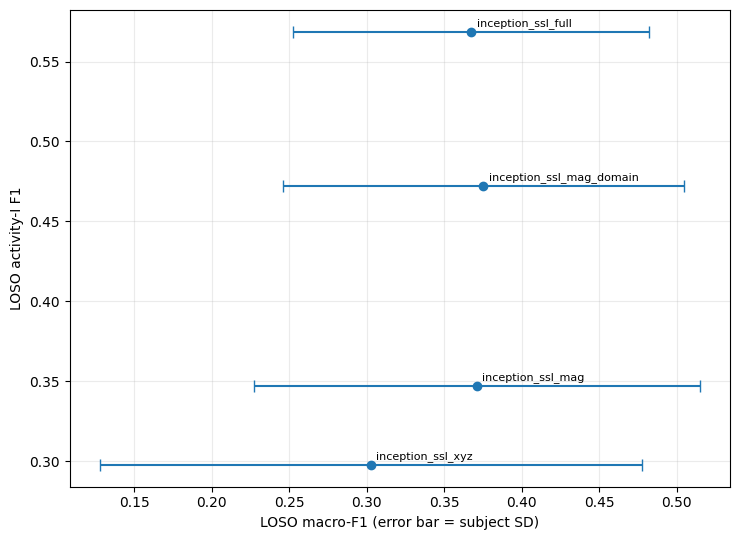

{
  "phase": "Phase 2B",
  "selected_encoder": "inception_ssl_full",
  "selection": {
    "model": "inception_ssl_full",
    "best_epoch": 8,
    "loso_accuracy": 0.4219612271786185,
    "loso_macro_f1": 0.3673330758291002,
    "loso_macro_f1_std": 0.11501044708343675,
    "loso_i_f1": 0.5687105752839993,
    "loso_ece": 0.3144323793386387,
    "selection_score": 0.45385252721062447,
    "magnitude": true,
    "domain": true,
    "reconstruction": true
  },
  "selected_results": {
    "model": "inception_ssl_full",
    "known_accuracy": 0.583030303030303,
    "known_macro_f1": 0.5883829601177977,
    "known_i_f1": 0.5666666666666667,
    "known_ece": 0.2678707191236955,
    "oracle_known_accuracy": 0.45696969696969697,
    "oracle_novel_macro_f1": 0.7224664799916841,
    "oracle_l_f1": 0.33191489361702126,
    "oracle_combined_macro_f1": 0.5785151936651106,
    "oracle_ece": 0.17034624053791322,
    "selected_on_development": true
  },
  "baseline_results": {
    "model": "phase0b_cont

416

In [9]:
metrics=['known_accuracy','known_i_f1','oracle_novel_macro_f1','oracle_l_f1']
fig,axes=plt.subplots(1,4,figsize=(19,4.8))
for ax,metric in zip(axes,metrics):
    colors=['#1b9e77' if m==SELECTED_ENCODER else '#858585' for m in results.model]
    ax.bar(results.model,results[metric],color=colors);ax.set_title(metric.replace('_',' '));ax.tick_params(axis='x',rotation=45,labelsize=8);ax.set_ylim(0,1);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2b_encoder_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(7.5,5.5));ax.errorbar(selection.loso_macro_f1,selection.loso_i_f1,xerr=selection.loso_macro_f1_std,fmt='o',capsize=4)
for row in selection.itertuples():ax.annotate(row.model,(row.loso_macro_f1,row.loso_i_f1),xytext=(4,4),textcoords='offset points',fontsize=8)
ax.set_xlabel('LOSO macro-F1 (error bar = subject SD)');ax.set_ylabel('LOSO activity-I F1');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase2b_loso_robustness.png',dpi=180,bbox_inches='tight');plt.show()

selected=results[results.model==SELECTED_ENCODER].iloc[0];baseline_row=results[results.model=='phase0b_contrastive'].iloc[0]
seldev=selection[selection.model==SELECTED_ENCODER].iloc[0]
gates={
 'G1_no_evaluation_subject_in_pretraining_or_selection':not bool(set(CFG.evaluation_subjects)&set(ssl_subjects)),
 'G2_activity_labels_excluded_from_encoder_training':True,
 'G3_selected_only_on_development':bool(selected.selected_on_development),
 'G4_cross_subject_variance':bool(seldev.loso_macro_f1_std<=CFG.loso_std_gate),
 'G5_known_accuracy':bool(selected.known_accuracy>=CFG.known_accuracy_gate and selected.known_accuracy>baseline_row.known_accuracy),
 'G6_known_I_f1':bool(selected.known_i_f1>=CFG.known_i_f1_gate),
 'G7_oracle_novel_macro_f1':bool(selected.oracle_novel_macro_f1>=CFG.oracle_novel_f1_gate),
 'G8_novel_L_f1':bool(selected.oracle_l_f1>=CFG.novel_l_f1_gate),
 'G9_known_calibration_improves':bool(selected.known_ece<baseline_row.known_ece),
 'G10_artifacts_complete':bool(len(selection)==len(CANDIDATES) and len(results)==len(embeddings) and len(per_class)>0)}
advance=bool(all(gates.values()))
decision={'phase':'Phase 2B','selected_encoder':SELECTED_ENCODER,'selection':{k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else int(v) if isinstance(v,(np.integer,)) else v) for k,v in seldev.to_dict().items()},
 'selected_results':{k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else v) for k,v in selected.to_dict().items()},
 'baseline_results':{k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else v) for k,v in baseline_row.to_dict().items()},
 'gates':gates,'rerun_phase1c_with_selected_encoder':advance,
 'label_policy':'Candidate encoders were trained without activity identities. Development known labels were used only by subject-held-out linear probes. Integration and evaluation labels were excluded from encoder training and selection; evaluation labels were opened only after freezing the selected checkpoint.',
 'config':asdict(CFG)}
(OUT/'phase2b_decision.json').write_text(json.dumps(decision,indent=2));print(json.dumps(decision,indent=2))

try:source=torch.load(OUT/f'{SELECTED_ENCODER}.pt',map_location='cpu',weights_only=False)
except TypeError:source=torch.load(OUT/f'{SELECTED_ENCODER}.pt',map_location='cpu')
rank_raw=selection.set_index('model').loc[SELECTED_ENCODER].to_dict()
rank={k:(bool(v) if isinstance(v,(np.bool_,bool)) else float(v) if isinstance(v,(np.floating,float)) else int(v) if isinstance(v,(np.integer,)) else v) for k,v in rank_raw.items()}
source['selection_rank']=rank;torch.save(source,OUT/'phase2b_selected_encoder.pt')
(OUT/'phase2b_selected_encoder.json').write_text(json.dumps({'selected_encoder':SELECTED_ENCODER,'development_selection':rank},indent=2))


In [10]:
report=f"""# FedVocabHAR Phase 2B Decision Report

## Decision

**Selected encoder:** {SELECTED_ENCODER}

**Rerun Phase 1C with selected encoder:** {decision['rerun_phase1c_with_selected_encoder']}

## Development robustness

- LOSO macro-F1: {seldev.loso_macro_f1:.4f}
- LOSO subject SD: {seldev.loso_macro_f1_std:.4f}
- LOSO activity-I F1: {seldev.loso_i_f1:.4f}

## Frozen final diagnostics

- Known accuracy: {selected.known_accuracy:.4f}
- Known activity I F1: {selected.known_i_f1:.4f}
- Oracle novel macro-F1: {selected.oracle_novel_macro_f1:.4f}
- Novel activity L F1: {selected.oracle_l_f1:.4f}
- Known calibration error: {selected.known_ece:.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nCandidate encoders were pretrained without activity labels. Development labels were confined to subject-held-out probes, and evaluation labels were sealed until selection was complete.\n'
(OUT/'FedVocabHAR_Phase2B_Decision_Report.md').write_text(report);print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 2B Decision Report

## Decision

**Selected encoder:** inception_ssl_full

**Rerun Phase 1C with selected encoder:** False

## Development robustness

- LOSO macro-F1: 0.3673
- LOSO subject SD: 0.1150
- LOSO activity-I F1: 0.5687

## Frozen final diagnostics

- Known accuracy: 0.5830
- Known activity I F1: 0.5667
- Oracle novel macro-F1: 0.7225
- Novel activity L F1: 0.3319
- Known calibration error: 0.2679

## Gates

- G1_no_evaluation_subject_in_pretraining_or_selection: **True**
- G2_activity_labels_excluded_from_encoder_training: **True**
- G3_selected_only_on_development: **True**
- G4_cross_subject_variance: **False**
- G5_known_accuracy: **False**
- G6_known_I_f1: **True**
- G7_oracle_novel_macro_f1: **True**
- G8_novel_L_f1: **False**
- G9_known_calibration_improves: **True**
- G10_artifacts_complete: **True**

Candidate encoders were pretrained without activity labels. Development labels were confined to subject-held-out probes, and evaluation labels were s

## Interpretation

- If all gates pass, freeze the selected encoder and rerun the unchanged Phase 1C admission and replay protocol.
- If development LOSO performance is strong but final performance fails, the remaining problem is unseen-subject domain shift; do not tune on evaluation subjects.
- If magnitude improves L but harms I, retain both XYZ and magnitude branches and test late fusion rather than lowering the gates.
- If every label-free candidate remains below the baseline on known recognition, the single watch-accelerometer formulation is insufficient and the paper should add another sensing modality or narrow its claim.
